# Análise da Geração de Energia Solar com Polars

## 1. Introdução e objetivos

Este notebook apresenta a segunda etapa da análise dos dados de geração de energia solar, na qual utilizaremos a biblioteca Polars para o processamento de um conjunto com mais de 100 mil registros.

O arquivo processado de geração será convertido do formato CSV para Parquet e consultado por meio de lazy evaluation. A partir dos dados, serão realizadas transformações e agregações com Polars, além de análises de correlação, dispersão e regressão linear.

A análise será concentrada nas medições de potência e na energia estimada a partir dos intervalos entre registros. As usinas P01 e P02 serão avaliadas separadamente nas análises que envolvem `dc_power`, por cuasa da diferença de escala que foi observada nessa variável em etapas anteriores.

Os principais objetivos para essa etapa são:

- Converter os dados de geração para o formato Parquet.
- Utilizar processamento lazy com Polars.
- Construir as variáveis temporais e estimar a energia gerada.
- Responder a perguntas estratégicas por meio de filtros e agregações.
- Analisar a relação entre `dc_power` e `ac_power`.
- Construir e avaliar modelos de regressão linear separadamente para cada usina.

## 2. Preparação do ambiente

In [1]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 3. Conversão e leitura dos dados

### 3.1 Leitura do arquivo CSV com Polars

In [2]:
csv_path = Path("../datasets/processados/generation_data.csv")

generation_df = pl.read_csv(
    csv_path,
    try_parse_dates=True
)

In [3]:
generation_df.head()

id,date_time,plant_id,plant_code,source_key,inverter_code,dc_power,ac_power,daily_yield,total_yield
str,datetime[μs],i64,str,str,str,f64,f64,f64,f64
"""000001-INV-P01-01""",2020-05-15 00:00:00,4135001,"""P01""","""1BY6WEcLGh8j5v7""","""INV-P01-01""",0.0,0.0,0.0,6.259559e6
"""000002-INV-P01-02""",2020-05-15 00:00:00,4135001,"""P01""","""1IF53ai7Xc0U56Y""","""INV-P01-02""",0.0,0.0,0.0,6.183645e6
"""000003-INV-P01-03""",2020-05-15 00:00:00,4135001,"""P01""","""3PZuoBAID5Wc2HD""","""INV-P01-03""",0.0,0.0,0.0,6.987759e6
"""000004-INV-P01-04""",2020-05-15 00:00:00,4135001,"""P01""","""7JYdWkrLSPkdwr4""","""INV-P01-04""",0.0,0.0,0.0,7.60296e6
"""000005-INV-P01-05""",2020-05-15 00:00:00,4135001,"""P01""","""McdE0feGgRqW7Ca""","""INV-P01-05""",0.0,0.0,0.0,7.158964e6


In [4]:
print(f"Linhas: {generation_df.height}")
print(f"Colunas: {generation_df.width}")

Linhas: 136476
Colunas: 10


### 3.2 Conversão para Parquet

In [5]:
parquet_path = Path(
    "../datasets/processados/generation_data.parquet"
)

pl.scan_csv(
    csv_path,
    try_parse_dates=True
).sink_parquet(
    parquet_path
)

### 3.3 Leitura lazy do Parquet

In [6]:
generation_lazy_df = pl.scan_parquet(parquet_path)

In [7]:
generation_lazy_df.head().collect()

id,date_time,plant_id,plant_code,source_key,inverter_code,dc_power,ac_power,daily_yield,total_yield
str,datetime[μs],i64,str,str,str,f64,f64,f64,f64
"""000001-INV-P01-01""",2020-05-15 00:00:00,4135001,"""P01""","""1BY6WEcLGh8j5v7""","""INV-P01-01""",0.0,0.0,0.0,6.259559e6
"""000002-INV-P01-02""",2020-05-15 00:00:00,4135001,"""P01""","""1IF53ai7Xc0U56Y""","""INV-P01-02""",0.0,0.0,0.0,6.183645e6
"""000003-INV-P01-03""",2020-05-15 00:00:00,4135001,"""P01""","""3PZuoBAID5Wc2HD""","""INV-P01-03""",0.0,0.0,0.0,6.987759e6
"""000004-INV-P01-04""",2020-05-15 00:00:00,4135001,"""P01""","""7JYdWkrLSPkdwr4""","""INV-P01-04""",0.0,0.0,0.0,7.60296e6
"""000005-INV-P01-05""",2020-05-15 00:00:00,4135001,"""P01""","""McdE0feGgRqW7Ca""","""INV-P01-05""",0.0,0.0,0.0,7.158964e6


### 3.4 Plano de consulta

Para demonstrar o planejamento de uma consulta lazy, serão selecionadas apenas as colunas relacionadas ao momento da medição, à identificação da usina e do inversor e às potências registradas.

In [8]:
query_plan = (
    generation_lazy_df
    .select(
        [
            "date_time",
            "plant_code",
            "inverter_code",
            "dc_power",
            "ac_power"
        ]
    )
)

In [9]:
print(query_plan.explain())

Parquet SCAN [../datasets/processados/generation_data.parquet]
PROJECT 5/10 COLUMNS
ESTIMATED ROWS: 136476


## 4. Preparação das variáveis analíticas

### 4.1 Variáveis temporais e intervalos

Para estimar a energia gerada, os registros serão ordenados por usina, inversor e data e hora. Em seguida, serão obtidos o horário e a potência da próxima medição do mesmo inversor.

A coluna `date` será utilizada para impedir que o último registro de um dia seja relacionado ao primeiro registro do dia seguinte.

In [10]:
generation_analysis_lazy_df = (
    generation_lazy_df
    .with_columns(
        pl.col("date_time").dt.date().alias("date"),
        pl.col("date_time").dt.hour().alias("hour")
    )
    .sort(
        [
            "plant_code",
            "inverter_code",
            "date_time"
        ]
    )
)

generation_analysis_lazy_df.collect_schema()

Schema([('id', String),
        ('date_time', Datetime(time_unit='us', time_zone=None)),
        ('plant_id', Int64),
        ('plant_code', String),
        ('source_key', String),
        ('inverter_code', String),
        ('dc_power', Float64),
        ('ac_power', Float64),
        ('daily_yield', Float64),
        ('total_yield', Float64),
        ('date', Date),
        ('hour', Int8)])

O horário e a potência da medição seguinte serão obtidos dentro de cada combinação de usina, inversor e data. Dessa forma, medições de inversores diferentes ou de dias consecutivos não serão relacionadas entre si.

In [11]:
group_columns = [
    "plant_code",
    "inverter_code",
    "date"
]

generation_analysis_lazy_df = (
    generation_analysis_lazy_df
    .with_columns(
        pl.col("date_time")
        .shift(-1)
        .over(group_columns)
        .alias("next_date_time"),

        pl.col("ac_power")
        .shift(-1)
        .over(group_columns)
        .alias("next_ac_power")
    )
)

In [12]:
generation_analysis_lazy_df.select(
    [
        "date_time",
        "plant_code",
        "inverter_code",
        "ac_power",
        "next_date_time",
        "next_ac_power"
    ]
).head(10).collect()

date_time,plant_code,inverter_code,ac_power,next_date_time,next_ac_power
datetime[μs],str,str,f64,datetime[μs],f64
2020-05-15 00:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:15:00,0.0
2020-05-15 00:15:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:30:00,0.0
2020-05-15 00:30:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:45:00,0.0
2020-05-15 00:45:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:00:00,0.0
2020-05-15 01:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:15:00,0.0
2020-05-15 01:15:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:30:00,0.0
2020-05-15 01:30:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:45:00,0.0
2020-05-15 01:45:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 02:00:00,0.0
2020-05-15 02:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 02:15:00,0.0


A duração entre cada medição e a medição seguinte será calculada em horas. Como os registros normalmente possuem frequência de 15 minutos, o esperado é que o intervalo com maior número de ocorrências seja de 0.25 hora.

In [13]:
generation_analysis_lazy_df = (
    generation_analysis_lazy_df
    .with_columns(
        (
            pl.col("next_date_time") - pl.col("date_time")
        )
        .dt.total_seconds()
        .truediv(3600)
        .alias("interval_hours")
    )
)

In [14]:
(
    generation_analysis_lazy_df
    .group_by("interval_hours")
    .len()
    .sort("interval_hours")
    .collect()
)

interval_hours,len
f64,u64
null,1464
0.25,134640
0.5,152
0.75,33
1.0,52
…,…
2.0,14
2.25,6
2.5,9


### 4.2 Energia estimada por intervalo

Serão considerados válidos somente os intervalos positivos de até 0.25 hora, porque considerar os intervalos maiores pode fazer com que as lacunas temporais sejam interpretadas como períodos contínuos de geração.

Assim como na etapa anterior, a energia de cada intervalo válido será estimada pelo método do trapézio, utilizando a média entre a potência atual e a potência seguinte, multiplicada pela duração do intervalo em horas.

In [15]:
valid_intervals_lazy_df = (
    generation_analysis_lazy_df
    .filter(
        pl.col("interval_hours").is_between(
            0,
            0.25,
            closed="right"
        )
    )
    .with_columns(
        (
            (pl.col("ac_power")+ pl.col("next_ac_power")) / 2 * pl.col("interval_hours")
        ).alias("estimated_energy")
    )
)

In [16]:
valid_intervals_lazy_df.select(
    [
        "date_time",
        "plant_code",
        "inverter_code",
        "ac_power",
        "next_ac_power",
        "interval_hours",
        "estimated_energy"
    ]
).head().collect()

date_time,plant_code,inverter_code,ac_power,next_ac_power,interval_hours,estimated_energy
datetime[μs],str,str,f64,f64,f64,f64
2020-05-15 00:00:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:15:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:30:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:45:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 01:00:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0


In [17]:
# Verificando o numero de intervalos válidos 

valid_intervals_lazy_df.select(
    pl.len().alias("valid_interval_count")
).collect()

valid_interval_count
u64
134640


In [18]:
# Verificando se a energia estimada apresenta valores nulos ou negativos e se a quantidade de registros corresponde aos intervalos considerados válidos

valid_intervals_lazy_df.select(
    pl.len().alias("record_count"),
    pl.col("estimated_energy").null_count().alias("null_count"),
    (pl.col("estimated_energy") < 0).sum().alias("negative_count"),
    pl.col("estimated_energy").min().alias("minimum"),
    pl.col("estimated_energy").max().alias("maximum")
).collect()

record_count,null_count,negative_count,minimum,maximum
u64,u64,u64,f64,f64
134640,0,0,0.0,338.793527


In [19]:
generation_analysis_df = (
    valid_intervals_lazy_df
    .collect()
)

## 5. Análises estratégicas com Polars

### 5.1 Potência média por horário e usina

### 5.2 Energia estimada por usina

### 5.3 Energia estimada por inversor

## 6. Correlação e dispersão

### 6.1 Correlação entre dc_power e ac_power

### 6.2 Gráficos de dispersão por usina

## 7. Regressão linear

### 7.1 Preparação dos dados

A regressão linear será utilizada para analisar a relação entre `dc_power`, que será definida como variável independente, e `ac_power`, que será definida como variável dependente.

Os modelos serão construídos separadamente para as usinas P01 e P02, visto que existe uma diferença de escala em `dc_power` que identificamos nos passos anteriores.

Serão considerados somente os registros em que `dc_power` e `ac_power` são maiores que zero. Dessa forma, os modelos representarão a relação entre as duas variáveis durante os períodos de geração ativa, evitando que a grande quantidade de registros noturnos iguais a zero influencie o ajuste.

In [20]:
# Separando os dados por usina

regression_data_by_plant = {}

for plant_code in ["P01", "P02"]:
    # plant_df = generation_analysis_df.filter(
    #     pl.col("plant_code") == plant_code
    # )

    plant_df = generation_analysis_df.filter(
        (pl.col("plant_code") == plant_code)
        & (pl.col("dc_power") > 0)
        & (pl.col("ac_power") > 0)
    )

    x = plant_df["dc_power"].to_numpy().reshape(-1, 1)
    y = plant_df["ac_power"].to_numpy()

    regression_data_by_plant[plant_code] = {
        "x": x,
        "y": y
    }

### 7.2 Modelos das usinas P01 e P02

Para cada usina, ajustaremos um modelo de regressão linear simples e serão obtidos o coeficiente angular, o intercepto, o coeficiente de determinação (R²) e o erro quadrático médio (MSE). Além disso, criaremos gráficos de dispersão com a reta estimada pelo modelo.

In [21]:
regression_results = {}

for plant_code, data in regression_data_by_plant.items():
    x = data["x"]
    y = data["y"]

    model = LinearRegression()
    model.fit(x, y)

    predictions = model.predict(x)

    regression_results[plant_code] = {
        "model": model,
        "coefficient": model.coef_[0],
        "intercept": model.intercept_,
        "r2": r2_score(y, predictions),
        "mse": mean_squared_error(y, predictions),
        "predictions": predictions
    }

In [22]:
regression_results_df = pl.DataFrame(
    {
        "plant_code": list(regression_results.keys()),
        "coefficient": [
            result["coefficient"]
            for result in regression_results.values()
        ],
        "intercept": [
            result["intercept"]
            for result in regression_results.values()
        ],
        "r2": [
            result["r2"]
            for result in regression_results.values()
        ],
        "mse": [
            result["mse"]
            for result in regression_results.values()
        ]
    }
)

regression_results_df

plant_code,coefficient,intercept,r2,mse
str,f64,f64,f64,f64
"""P01""",0.097611,1.085963,0.999986,1.916079
"""P02""",0.976351,0.869875,0.999988,1.641914


In [23]:
# Mostrando como ficaram as equações das retas

for plant_code, result in regression_results.items():
    print(
        f"{plant_code}: "
        f"ac_power = {result['coefficient']:.4f} "
        f"* dc_power + {result['intercept']:.4f}"
    )

P01: ac_power = 0.0976 * dc_power + 1.0860
P02: ac_power = 0.9764 * dc_power + 0.8699


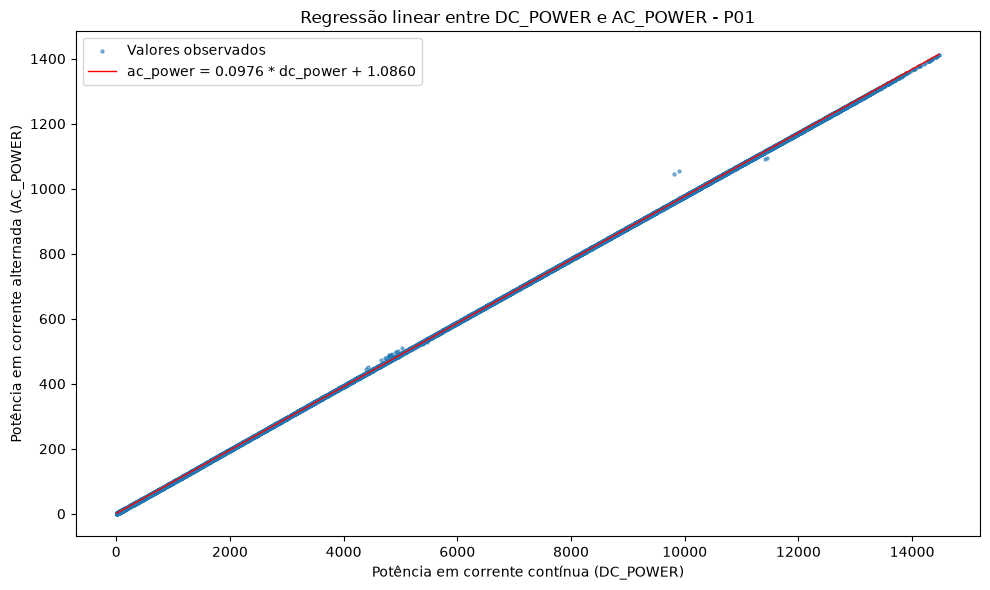

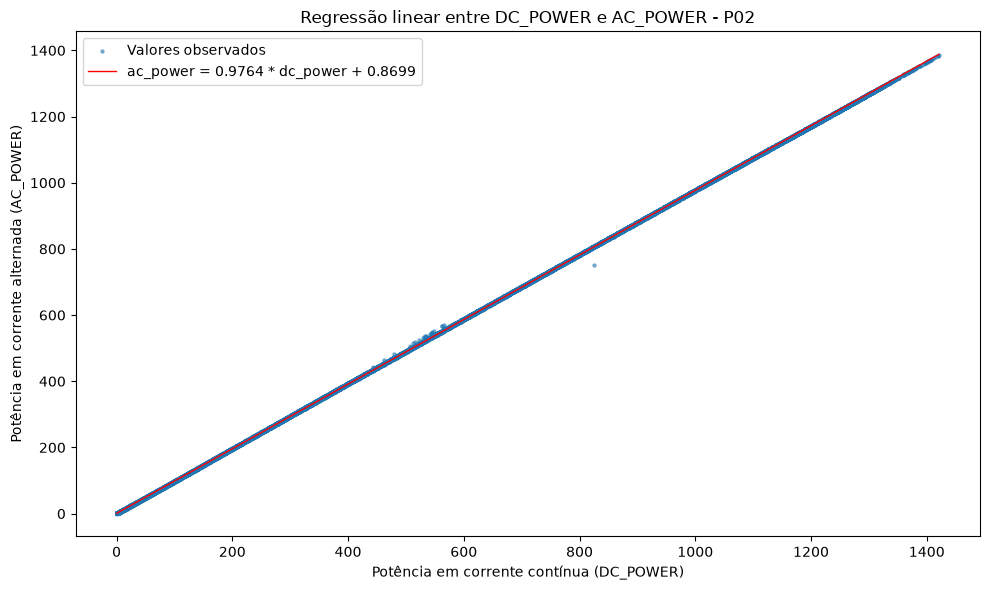

In [24]:
for plant_code, data in regression_data_by_plant.items():
    x = data["x"]
    y = data["y"]
    predictions = regression_results[plant_code]["predictions"]

    sorted_indices = np.argsort(x[:, 0])

    plt.figure(figsize=(10, 6))

    plt.scatter(
        x[:, 0],
        y,
        alpha=0.5,
        s=5,
        label="Valores observados"
    )

    plt.plot(
        x[sorted_indices, 0],
        predictions[sorted_indices],
        color="red",
        linewidth=1,
        label= f"ac_power = {regression_results[plant_code]['coefficient']:.4f} * dc_power + {regression_results[plant_code]['intercept']:.4f}"
    )

    plt.title(
        f"Regressão linear entre DC_POWER e AC_POWER - {plant_code}"
    )
    plt.xlabel("Potência em corrente contínua (DC_POWER)")
    plt.ylabel("Potência em corrente alternada (AC_POWER)")
    plt.legend()
    plt.tight_layout()
    plt.show()

Os modelos apresentaram ajustes próximos do perfeito, em ambos os casos com R² superior a 0.9999. Tal resultado é coerente de considerarmos a relação física direta entre as potências em corrente contínua e alternada durante os períodos de geração ativa.

Entretanto, como observado em etapas anteriores, um ponto de atenção aqui é o coeficiente angular da P02 foi aproximadamente dez vezes maior que o da P01. Essa diferença reforça a hipótese levantada anteriormente de que `dc_power` na P01 está registrada em uma escala aproximadamente dez vezes maior do que deveria. Sendo assim, os coeficientes dos modelos não devem ser comparados como indicadores de eficiência das usinas, ou seja, não é possível afirmar com os dados que temos que P02 é dez vezes mais eficiente que a P01 ou dizer que o coeficiente de 0.976 da P01 representa uma eficiência de 9.76%.

### 7.3 Avaliação e comparação dos modelos